# Project 2

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import drive
drive.mount('/content/drive');
filepath = '/content/drive/MyDrive/MAL-manga.csv';
df = pd.read_csv(filepath);
print(df.head(1));
print(df.shape);

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Unnamed: 0        Title  Rank   Type Volumes            Published  Members  \
0           0  City Hunter   460  Manga      35  Feb 1985 - Nov 1991    14690   

                                        page_url  \
0  https://myanimelist.net/manga/792/City_Hunter   

                                           image_url  Score  
0  https://cdn.myanimelist.net/r/100x140/images/m...   8.16  
(17811, 10)


## Problem Statement

**Dataset Description**

The dataset I picked is from Kaggle and can be found at this link: https://www.kaggle.com/datasets/nikhil1e9/myanimelist-anime-and-manga?resource=download&select=MAL-manga.csv. This link contains two datasets, I am using the manga dataset. This data was collected by scraping the website MyAnimeList and contains 17,811 entries. For each entry in the dataset, it includes the title, ranking on the website, number of members who have reviewed it, dates published, volume count, review scores, the page url, and the image url.


**Target Variable Analysis**

The Target Variable is Score, which is a continuous numerical variable. It's distribution is approximately bell-shaped, centered around 7. Most manga scores fall between 6 and 8. The scores range from a minimum of 2.42 to a maximum of 9.47, with a median of 6.97.

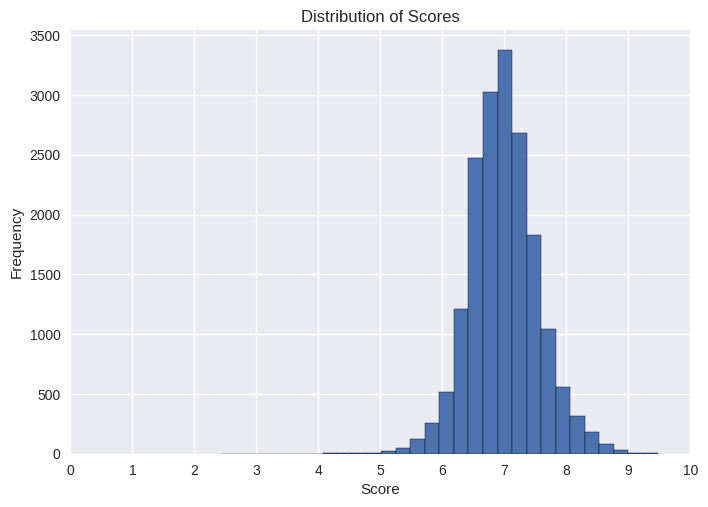

count    17811.000000
mean         6.989322
std          0.548498
min          2.430000
25%          6.640000
50%          6.970000
75%          7.320000
max          9.470000
Name: Score, dtype: float64


In [19]:
plt.style.use('seaborn-v0_8');
plt.hist(df['Score'], bins=30, edgecolor='black');
plt.xticks(np.arange(0, 11, 1));
plt.xlabel('Score');
plt.ylabel('Frequency');
plt.title('Distribution of Scores');
plt.show();
print(df['Score'].describe());

**Prediction Goal**

My goal is to build a regression model to predict manga Score based on features such as member engagement on the website, volume length, and media format. These features will not explain everything behind a score, but do contain useful information.

## Basic Data Cleaning


**Dropping Unwanted Features**

The Title, page_url, and image_url are identifiers for entries into the database but not useful in predicting the target variable. Published is a range and is excluded. Rank is closely tied to Score, so it is excluded. Unnamed: 0 is an ID column and not a manga characteristic. I retained Type, Volumes, Members, and Score

In [20]:
df = df.drop('Rank', axis=1);
df = df.drop('Title', axis=1);
df = df.drop('page_url', axis=1);
df = df.drop('image_url', axis=1);
df = df.drop('Published', axis=1);
df = df.drop('Unnamed: 0', axis=1);
print(df.shape);

(17811, 4)


**Address Missing Values**

The Volume column lists all null values as "?" and has a data type of object. I changed the "?" to null and changed the data type of Volume to float. With this, only Volumes contained null values, so they were filled with the median number of Volumes.

In [21]:
print(df.dtypes);
df = df.replace('?', np.nan);
# Discovered this method from https://www.geeksforgeeks.org/pandas/change-data-type-for-one-or-more-columns-in-pandas-dataframe/
df['Volumes'] = df['Volumes'].astype(float);
print(df.isnull().sum());
df['Volumes'] = df['Volumes'].fillna(df['Volumes'].median());
print(df.shape);


Type        object
Volumes     object
Members      int64
Score      float64
dtype: object
Type          0
Volumes    5175
Members       0
Score         0
dtype: int64
(17811, 4)


**Remove Duplicates**

There were 39 duplicate rows dropped from the dataset.

In [22]:
df = df.drop_duplicates();
print(df.shape);

(17772, 4)


**Inconsistent Categorical Inputs**

There are no inconsistent categorical inputs.

In [23]:
print(df['Type'].unique());

['Manga' 'One-shot' 'Manhwa' 'Light-Novel' 'Doujinshi' 'Manhua' 'Novel']


**Outlier Removal**

Both Volumes and Members contained outliers. For Volumes, I removed rows with more than 75 volumes due to the unusally large values they have. For Members, I removed rows with more than 300,000 members for the same reason as Volumes. These thresholds were picked based on the boxplot to filter out the unusually high values and reduce their influence on analysis.

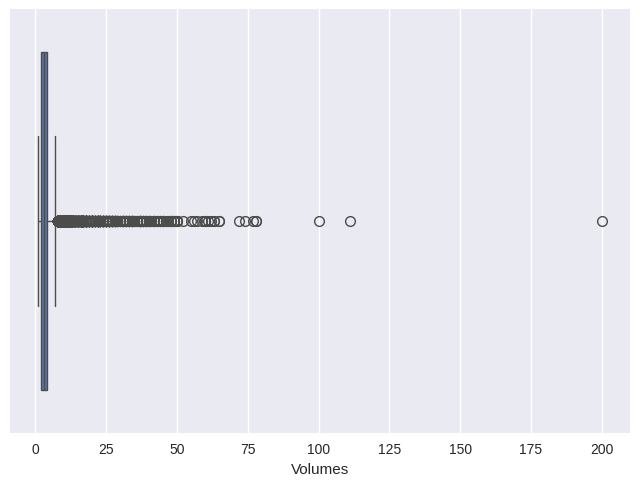

In [24]:
sns.boxplot(data=df, x=df['Volumes']);

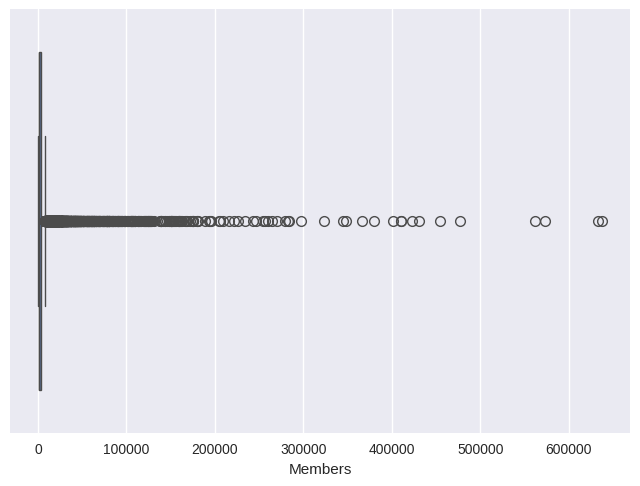

In [25]:
sns.boxplot(data=df, x=df['Members']);

In [26]:
df = df[df['Volumes'] < 75];
df = df[df['Members'] < 300000];
print(df.shape);

(17750, 4)


**Dummy Variables**

Due to Type being categorical, I changed them into dummy vaiables.

In [27]:
df = pd.get_dummies(df, columns=['Type'], drop_first=True);
print(df.head(1));

   Volumes  Members  Score  Type_Light-Novel  Type_Manga  Type_Manhua  \
0     35.0    14690   8.16             False        True        False   

   Type_Manhwa  Type_Novel  Type_One-shot  
0        False       False          False  


##Feature Engineering And Feature Selection

**Graphs**

Looking at the Correlation Heatmap, the strongest correlation with Score is Members, which is 0.396. A moderatte positive Score is shown with Volumes, which the correlation is 0.323. Among media types, Type_Light-Novel shows a moderate positive correlation with Score at 0.204, while the weakest is Type_One-shot with a negative correlation of -0.262. Across the other media types, they show a weak correlation with the target variable Score. There is also a weak correlation between Volumes and Members, with a correlation of 0.282, thus they do not affect each other. All the media types share weak or negative relationships with Volumes and Members, so they also do not affect them.

                   Volumes   Members     Score  Type_Light-Novel  Type_Manga  \
Volumes           1.000000  0.282414  0.322342          0.028499    0.036055   
Members           0.282414  1.000000  0.396211         -0.013627    0.083939   
Score             0.322342  0.396211  1.000000          0.203658    0.036600   
Type_Light-Novel  0.028499 -0.013627  0.203658          1.000000   -0.420591   
Type_Manga        0.036055  0.083939  0.036600         -0.420591    1.000000   
Type_Manhua      -0.003791 -0.009335  0.017796         -0.021826   -0.170864   
Type_Manhwa       0.023760 -0.030627  0.045795         -0.066101   -0.517477   
Type_Novel       -0.012125 -0.001447  0.077300         -0.011288   -0.088371   
Type_One-shot    -0.081307 -0.075569 -0.261977         -0.071899   -0.562865   

                  Type_Manhua  Type_Manhwa  Type_Novel  Type_One-shot  
Volumes             -0.003791     0.023760   -0.012125      -0.081307  
Members             -0.009335    -0.030627   -0.001447 

<Axes: >

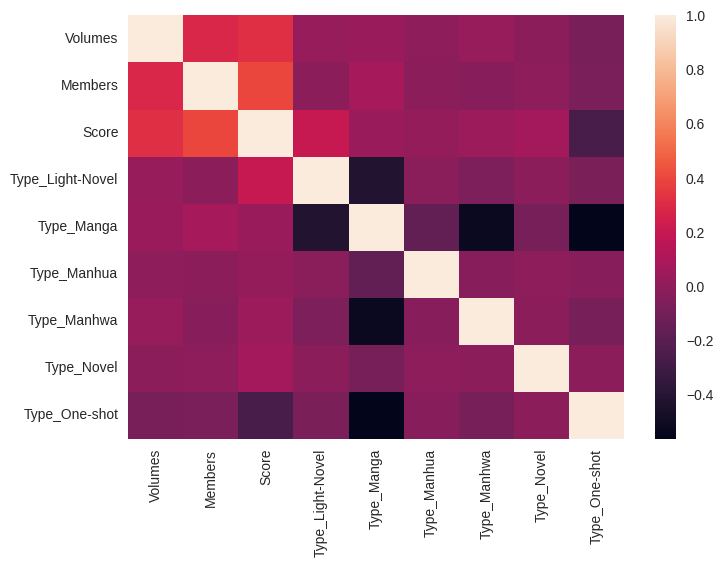

In [28]:
print(df.corr());
sns.heatmap(df.corr())

**ANOVA F-Tests**

When running ANOVA F-Tests, Volumes returns a score of 2066.61 and showing a P-Value of 0.0, showing it has a significant relationship with Score. Members returns a score of 3313.97 and showing a P-Value of 0.0, showing it also as a significant relationship with Members. Type has a score of 174.61 and a P-Value of 1.13 x 10^39 showing it is also significant in predicting manga scores. This means all features tested are signifigant and are all kept.

In [29]:
x = df.loc[:, ['Volumes', 'Members']];
y = df.loc[:, 'Score'];
fs = SelectKBest(score_func=f_regression, k='all');
bestFeatures = fs.fit(x, y);
print("Scores:", bestFeatures.scores_);
print("P-Values:", bestFeatures.pvalues_);

Scores: [2057.91879032 3304.9527339 ]
P-Values: [0. 0.]


In [30]:
x2 = df.loc[:, ['Type_Light-Novel', 'Type_Manga', 'Type_Manhua', 'Type_Manhwa', 'Type_Novel', 'Type_One-shot']];
y2 = df.loc[:, 'Score'];
fs2 = SelectKBest(score_func=f_regression, k='all');
bestFeatures2 = fs2.fit(x2, y2);
print("Score:", bestFeatures2.scores_);
print("P-Values:", bestFeatures2.pvalues_);

Score: [ 767.98168779   23.80678643    5.62221992   37.29897571  106.68770705
 1307.84052261]
P-Values: [1.62200893e-165 1.07430066e-006 1.77447865e-002 1.03447797e-009
 6.13212902e-025 2.19418726e-276]


## Building The Prediction Model

**Validation Strategy**

I used train_test_split to prevent overfitting from occuring in the prediction model. The data is split 80% training data and 20% test data.

In [31]:

x = df.loc[:, ['Volumes', 'Members', 'Type_Light-Novel', 'Type_Manga', 'Type_Manhua', 'Type_Manhwa', 'Type_Novel', 'Type_One-shot']];
y = df.loc[:, ['Score']];
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=45);

**Standardization**

I applied a StandardScaler to normalize the numerical features and dummy features. This ensures that features with larger numerical magnitudes do not dominate the prediction model. Because Score is a continuous target variable, SMOTE and undersampling are not required.

In [32]:
scaler = StandardScaler();
x_train = scaler.fit_transform(x_train);
x_test = scaler.transform(x_test);

**Algorithm Choice**

Due to Score itself being continuous, I picked to use Linear Regression as my prediction model.

In [33]:
model = LinearRegression();
model.fit(x_train, y_train);

**Evaluation Metrics**

The Mean Absolute Error of this model is 0.36, meaning the predicted Scores are 0.36 points off. The Root Mean Square Error is 0.47, showing that there are no big prediction errors. The R2 Score is 0.27, meaning there is a 27% variance in the target variable Scores. This 27% shows that linear features alone are not enought to capture how scoring is done.

In [34]:
y_predict = model.predict(x_test);
scores = model.score(x_test, y_test);
mae = mean_absolute_error(y_test, model.predict(x_test));
rmse = np.sqrt(mean_squared_error(y_test, model.predict(x_test)));
print("MAE:", round(mae, 2));
print("RMSE:", round(rmse, 2));
print("R^2 Score:", round(scores,2));

MAE: 0.36
RMSE: 0.47
R^2 Score: 0.27


**Why The Model Struggled**

Manga scores are driven by far more features not in this dataset, like themes, genres, artwork, and the author.